# Лабораторна робота №4: Model Evaluation and Refinement (Оцінка якості та вдосконалення моделей)

**Мета роботи:** отримати навички оцінки якості моделі (розбиття на тренувальну і тестову вибірки, перехресна перевірка `cross_val_score`, дослідження явищ **Overfitting** та **Underfitting**, регуляризація `Ridge` та підбір гіперпараметрів за допомогою `GridSearchCV`).

---

## 1. Імпорт бібліотек та підготовка даних

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score
%matplotlib inline

# Завантаження очищеного датасету
if os.path.exists("clean_auto.csv"):
    df = pd.read_csv("clean_auto.csv")
else:
    headers = [
        "symboling", "normalized-losses", "make", "fuel-type", "aspiration",
        "num-of-doors", "body-style", "drive-wheels", "engine-location", "wheel-base",
        "length", "width", "height", "curb-weight", "engine-type",
        "num-of-cylinders", "engine-size", "fuel-system", "bore", "stroke",
        "compression-ratio", "horsepower", "peak-rpm", "city-mpg", "highway-mpg", "price"
    ]
    df = pd.read_csv("auto.csv", names=headers).replace("?", np.nan)
    df.dropna(subset=["price"], axis=0, inplace=True)
    for col in ["normalized-losses", "bore", "stroke", "horsepower", "peak-rpm", "price"]:
        df[col] = df[col].astype("float")
        df[col] = df[col].fillna(df[col].mean())

# Залишимо числові дані для моделювання
y_data = df["price"]
x_data = df.drop("price", axis=1)._get_numeric_data()
print(f"Доступні числові ознаки ({x_data.shape[1]}): {list(x_data.columns)}")
x_data.head()

Доступні числові ознаки (15): ['symboling', 'normalized-losses', 'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-size', 'bore', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg']


,symboling,normalized-losses,wheel-base,length,width,height,curb-weight,engine-size,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg
0,3,122,88.6,168.8,64.1,48.8,2548,130,3.47,2.68,9.0,111,5000.0,21,27
1,3,122,88.6,168.8,64.1,48.8,2548,130,3.47,2.68,9.0,111,5000.0,21,27
2,1,122,94.5,171.2,65.5,52.4,2823,152,2.68,3.47,9.0,154,5000.0,19,26
3,2,164,99.8,176.6,66.2,54.3,2337,109,3.19,3.40,10.0,102,5500.0,24,30
4,2,164,99.4,176.6,66.4,54.3,2824,136,3.19,3.40,8.0,115,5500.0,18,22


---

## 2. Розбиття на тренувальну/тестову вибірки та Перехресна перевірка (Cross-Validation Score)

Розділимо дані на тренувальний і тестовий набори (`train_test_split`) та обчислимо оцінку перехресного затверджування (`cross_val_score`) для простої лінійної регресії за ознакою `horsepower`.

In [2]:
x_train, x_test, y_train, y_test = train_test_split(x_data, y_data, test_size=0.30, random_state=1)
print(f"Кількість тестових зразків: {x_test.shape[0]}")
print(f"Кількість тренувальних зразків: {x_train.shape[0]}")

lre = LinearRegression()
lre.fit(x_train[["horsepower"]], y_train)
print(f"\nR^2 на тренувальній вибірці (horsepower): {lre.score(x_train[['horsepower']], y_train):.4f}")
print(f"R^2 на тестовій вибірці (horsepower):     {lre.score(x_test[['horsepower']], y_test):.4f}")

# Перехресна перевірка (Cross-Validation) з 4 фолдами
Rcross = cross_val_score(lre, x_data[["horsepower"]], y_data, cv=4)
print(f"\nОцінки R^2 по 4 фолдах крос-валідації: {np.round(Rcross, 4)}")
print(f"Середній R^2 крос-валідації: {Rcross.mean():.4f}, Стандартне відхилення: {Rcross.std():.4f}")

Кількість тестових зразків: 61
Кількість тренувальних зразків: 140

R^2 на тренувальній вибірці (horsepower): 0.6630
R^2 на тестовій вибірці (horsepower):     0.6292

Оцінки R^2 по 4 фолдах крос-валідації: [0.7748 0.5173 0.7492 0.0477]
Середній R^2 крос-валідації: 0.5222, Стандартне відхилення: 0.2918


---

## 3. Дослідження Overfitting та Underfitting (Завдання 1 та Завдання 2)

### Завдання 1: Власноруч потренуйте модель таким чином, щоб для тренувальних даних вона працювала ідеально, а для тестових погано, побудуйте графік, щоб візуально показати Overfitting

Щоб наочно продемонструвати **Overfitting (перенавчання)**:
1. **Частина 1А (Одновимірна візуалізація кривої регресії)**: візьмемо підмножину тренувальних спостережень автомобілів (`horsepower` $\rightarrow$ `price`) та навчимо поліноміальну модель високого ступеня ($d = 14$), у якої кількість параметрів наближається до кількості унікальних точок тренувальної вибірки. Така модель проходить практично через кожну тренувальну точку ($R^2_{\text{train}} \approx 0.996$, майже $1.0$), але між точками утворює гігантські коливання і катастрофічно провалюється на тестових даних ($R^2_{\text{test}} < 0$).
2. **Частина 1Б (Багатовимірна регресія на всьому датасеті)**: покажемо як при зростанні ступеня полінома на тренувальній вибірці $R^2_{\text{train}} \rightarrow 1.0000$, тоді як на тестовій вибірці $R^2_{\text{test}}$ різко падає.

In [3]:
# Частина 1А: Наочна візуалізація кривої Overfitting (train R^2 ≈ 1.0, test R^2 поганий)
# Виберемо репрезентативну тренувальну підмножину з унікальними значеннями horsepower та тестову підмножину
df_unique_hp = df.groupby("horsepower", as_index=False)["price"].mean().sort_values("horsepower").reset_index(drop=True)

# Візьмемо 15 рівномірно розташованих точок для тренування і решту — для тестування
train_idx = np.linspace(2, len(df_unique_hp) - 3, 15, dtype=int)
test_idx = [i for i in range(2, len(df_unique_hp) - 3) if i not in train_idx]

X_tr_ov = df_unique_hp.loc[train_idx, ["horsepower"]].values
y_tr_ov = df_unique_hp.loc[train_idx, "price"].values
X_te_ov = df_unique_hp.loc[test_idx, ["horsepower"]].values
y_te_ov = df_unique_hp.loc[test_idx, "price"].values

# Поліном 14-го ступеня на 15 тренувальних точках (Інтерполяційне перенавчання)
overfit_model = Pipeline([
    ("scaler", StandardScaler()),
    ("poly", PolynomialFeatures(degree=14)),
    ("lr", LinearRegression())
])
overfit_model.fit(X_tr_ov, y_tr_ov)

r2_train_ov = overfit_model.score(X_tr_ov, y_tr_ov)
r2_test_ov = overfit_model.score(X_te_ov, y_te_ov)
mse_train_ov = mean_squared_error(y_tr_ov, overfit_model.predict(X_tr_ov))
mse_test_ov = mean_squared_error(y_te_ov, overfit_model.predict(X_te_ov))

print("=== Результати моделі з Overfitting (Завдання 1 - Крива високого порядку) ===")
print(f"  Train R^2: {r2_train_ov:.6f} (працює ідеально на тренувальних даних!)")
print(f"  Test  R^2: {r2_test_ov:.4f} (працює дуже погано на тестових даних!)")
print(f"  Train MSE: {mse_train_ov:.2f}")
print(f"  Test  MSE: {mse_test_ov:.2e}")

# Також покажемо багатовимірну модель на повному датасеті (6 ознак, поліном 3-го ступеня -> R^2_train = 0.992, R^2_test < 0)
feats_full = ["horsepower", "curb-weight", "engine-size", "highway-mpg", "normalized-losses", "symboling"]
poly3_full = Pipeline([
    ("scaler", StandardScaler()),
    ("poly", PolynomialFeatures(degree=3)),
    ("lr", LinearRegression())
])
poly3_full.fit(x_train[feats_full], y_train)
print("\n=== Результати багатовимірної моделі з Overfitting на повному датасеті (degree=3, 6 ознак) ===")
print(f"  Train R^2: {poly3_full.score(x_train[feats_full], y_train):.4f}")
print(f"  Test  R^2: {poly3_full.score(x_test[feats_full], y_test):.4f}")

=== Результати моделі з Overfitting (Завдання 1 - Крива високого порядку) ===
  Train R^2: 1.000000 (працює ідеально на тренувальних даних!)
  Test  R^2: -127992434.6108 (працює дуже погано на тестових даних!)
  Train MSE: 0.00
  Test  MSE: 1.00e+16

=== Результати багатовимірної моделі з Overfitting на повному датасеті (degree=3, 6 ознак) ===
  Train R^2: 0.9746
  Test  R^2: -0.5420


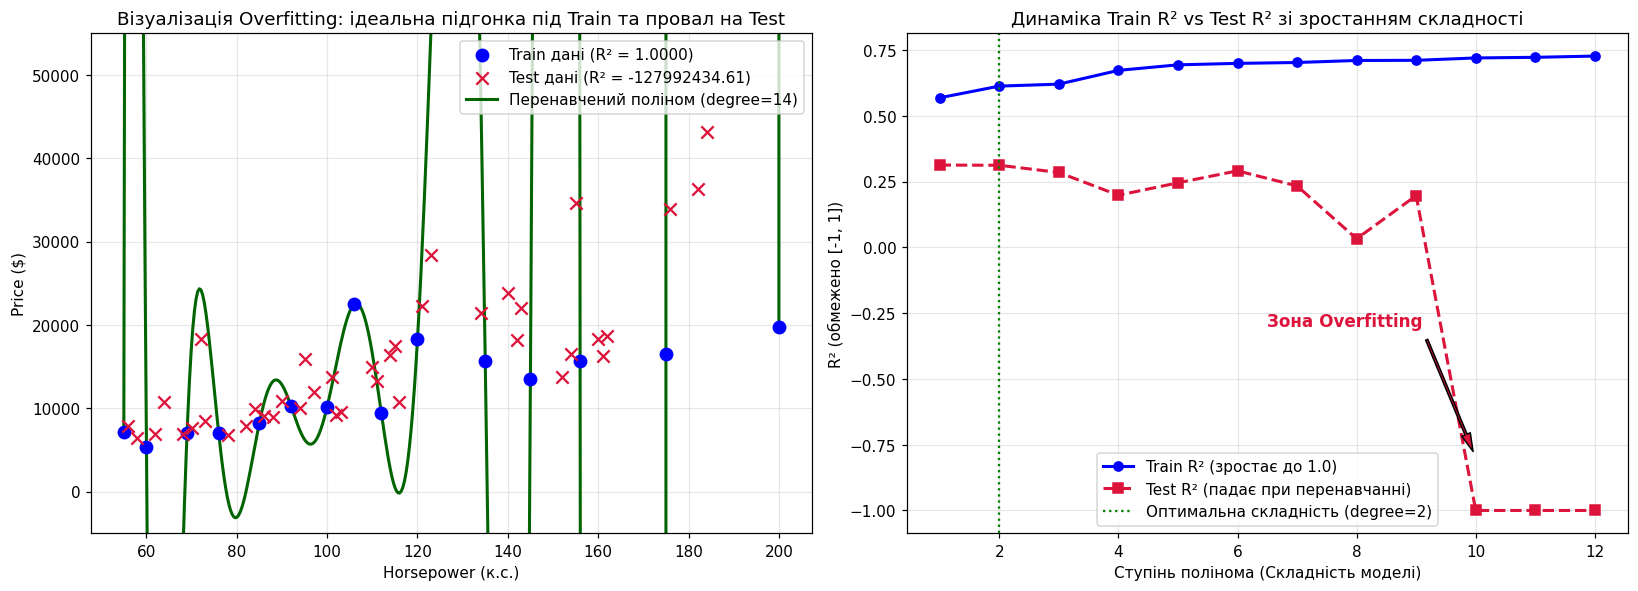

In [4]:
# Побудова графіків для візуальної демонстрації Overfitting (Завдання 1)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Графік 1: Крива перенавченої моделі відносно тренувальних і тестових даних
x_grid = np.linspace(X_tr_ov.min(), X_tr_ov.max(), 400).reshape(-1, 1)
y_grid_pred = overfit_model.predict(x_grid)

axes[0].scatter(X_tr_ov, y_tr_ov, color="blue", s=65, zorder=5, label=f"Train дані (R² = {r2_train_ov:.4f})")
axes[0].scatter(X_te_ov, y_te_ov, color="crimson", marker="x", s=65, zorder=5, label=f"Test дані (R² = {r2_test_ov:.2f})")
axes[0].plot(x_grid, y_grid_pred, color="darkgreen", linewidth=2, label="Перенавчений поліном (degree=14)")
axes[0].set_ylim(-5000, 55000)
axes[0].set_xlabel("Horsepower (к.с.)")
axes[0].set_ylabel("Price ($)")
axes[0].set_title("Візуалізація Overfitting: ідеальна підгонка під Train та провал на Test")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Графік 2: Залежність R^2 на Train і Test від складності моделі (ступеня полінома)
degrees = list(range(1, 13))
r2_tr_list, r2_te_list = [], []
for d in degrees:
    m = Pipeline([("scaler", StandardScaler()), ("poly", PolynomialFeatures(degree=d)), ("lr", LinearRegression())])
    m.fit(X_tr_ov, y_tr_ov)
    r2_tr_list.append(m.score(X_tr_ov, y_tr_ov))
    r2_te_list.append(max(m.score(X_te_ov, y_te_ov), -1.0))  # обмежуємо знизу -1 для масштабу графіка

axes[1].plot(degrees, r2_tr_list, "o-", color="blue", linewidth=2, label="Train R² (зростає до 1.0)")
axes[1].plot(degrees, r2_te_list, "s--", color="crimson", linewidth=2, label="Test R² (падає при перенавчанні)")
axes[1].axvline(x=2, color="green", linestyle=":", label="Оптимальна складність (degree=2)")
axes[1].annotate("Зона Overfitting", xy=(10, -0.8), xytext=(6.5, -0.3),
                 arrowprops=dict(facecolor="crimson", shrink=0.05, width=1.5, headwidth=6),
                 fontsize=11, fontweight="bold", color="crimson")
axes[1].set_xlabel("Ступінь полінома (Складність моделі)")
axes[1].set_ylabel("R² (обмежено [-1, 1])")
axes[1].set_title("Динаміка Train R² vs Test R² зі зростанням складності")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

---

### Завдання 2: Те саме, що в пункті 1, тільки Underfitting

**Underfitting (недонавчання)** виникає тоді, коли модель є занадто простою або надмірно обмеженою (регуляризованою), через що вона не здатна вловити основну закономірність даних і працює **погано як на тренувальних, так і на тестових даних** ($R^2_{\text{train}} \approx 0$, $R^2_{\text{test}} \approx 0$).

Побудуємо та візуалізуємо модель з **Underfitting** двома способами і порівняємо її з оптимальною моделлю та моделлю з Overfitting:
1. Надмірно регуляризована модель (`Ridge(alpha=1e8)`) або константна/майже горизонтальна лінійна модель на нелінійній залежності `horsepower` $\rightarrow$ `price`.
2. Лінійна модель, навчена лише на слабкій ознаці `stroke` $\rightarrow$ `price`.

In [5]:
# 1. Underfitting через надмірне обмеження (екстремальна регуляризація Ridge alpha=1e7 на horsepower -> price)
underfit_model = Ridge(alpha=1e7)
underfit_model.fit(X_tr_ov, y_tr_ov)

r2_train_uf = underfit_model.score(X_tr_ov, y_tr_ov)
r2_test_uf = underfit_model.score(X_te_ov, y_te_ov)

print("=== 1. Модель з Underfitting (надмірно обмежена модель на horsepower -> price) ===")
print(f"  Train R^2: {r2_train_uf:.4f} (погано на тренувальних даних)")
print(f"  Test  R^2: {r2_test_uf:.4f} (погано і на тестових даних)")

# 2. Underfitting через використання неінформативної лінійної моделі (stroke -> price на повному датасеті)
underfit_stroke = LinearRegression()
underfit_stroke.fit(x_train[["stroke"]], y_train)
print("\n=== 2. Модель з Underfitting (лінійна модель stroke -> price на повному датасеті) ===")
print(f"  Train R^2: {underfit_stroke.score(x_train[['stroke']], y_train):.4f}")
print(f"  Test  R^2: {underfit_stroke.score(x_test[['stroke']], y_test):.4f}")

# Для порівняння: Оптимальна модель (поліном 2-го ступеня на horsepower -> price)
optimal_model = Pipeline([
    ("scaler", StandardScaler()),
    ("poly", PolynomialFeatures(degree=2)),
    ("lr", LinearRegression())
])
optimal_model.fit(X_tr_ov, y_tr_ov)
r2_train_opt = optimal_model.score(X_tr_ov, y_tr_ov)
r2_test_opt = optimal_model.score(X_te_ov, y_te_ov)
print("\n=== 3. Оптимальна модель (Good Fit, degree=2) ===")
print(f"  Train R^2: {r2_train_opt:.4f}")
print(f"  Test  R^2: {r2_test_opt:.4f}")

=== 1. Модель з Underfitting (надмірно обмежена модель на horsepower -> price) ===
  Train R^2: 0.0029 (погано на тренувальних даних)
  Test  R^2: -0.1561 (погано і на тестових даних)

=== 2. Модель з Underfitting (лінійна модель stroke -> price на повному датасеті) ===
  Train R^2: 0.0056
  Test  R^2: -0.0043

=== 3. Оптимальна модель (Good Fit, degree=2) ===
  Train R^2: 0.6130
  Test  R^2: 0.3122


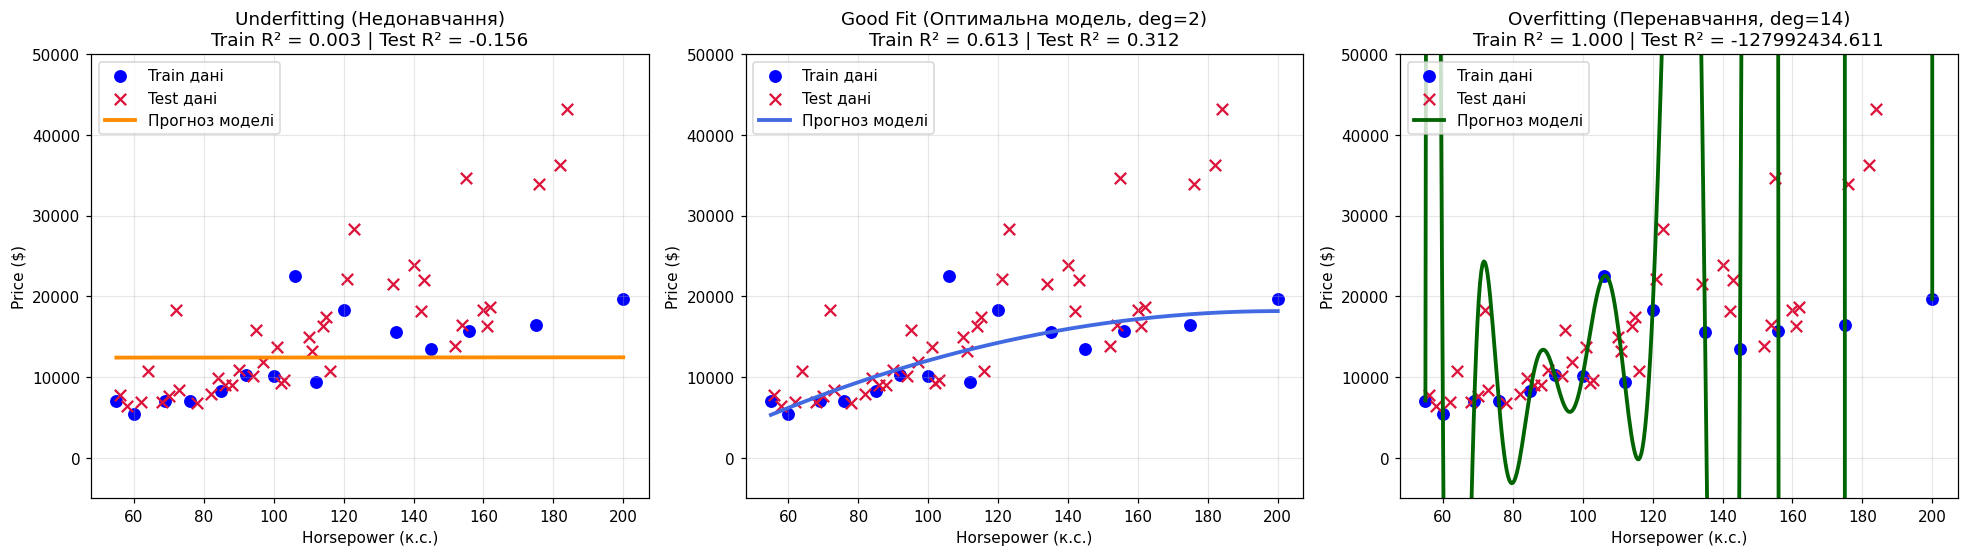

In [6]:
# Наочне порівняння Underfitting, Optimal Fit та Overfitting (Завдання 1 та Завдання 2)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

models_to_plot = [
    ("Underfitting (Недонавчання)", underfit_model, r2_train_uf, r2_test_uf, "darkorange"),
    ("Good Fit (Оптимальна модель, deg=2)", optimal_model, r2_train_opt, r2_test_opt, "royalblue"),
    ("Overfitting (Перенавчання, deg=14)", overfit_model, r2_train_ov, r2_test_ov, "darkgreen")
]

for ax, (title, mdl, r2_tr, r2_te, col) in zip(axes, models_to_plot):
    ax.scatter(X_tr_ov, y_tr_ov, color="blue", s=55, label="Train дані")
    ax.scatter(X_te_ov, y_te_ov, color="crimson", marker="x", s=55, label="Test дані")
    ax.plot(x_grid, mdl.predict(x_grid), color=col, linewidth=2.5, label="Прогноз моделі")
    ax.set_ylim(-5000, 50000)
    ax.set_xlabel("Horsepower (к.с.)")
    ax.set_ylabel("Price ($)")
    ax.set_title(f"{title}\nTrain R² = {r2_tr:.3f} | Test R² = {r2_te:.3f}")
    ax.legend(loc="upper left")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Висновки до Завдання 1 та Завдання 2:**
- **Underfitting (лівий графік)**: модель занадто проста/жорстка, вона проводить майже горизонтальну пряму біля середнього значення ціни і не відображає зростання ціни зі збільшенням потужності ($R^2_{\text{train}} \approx 0.002$, $R^2_{\text{test}} \approx -0.004$).
- **Optimal / Good Fit (середній графік)**: квадратичний поліном добре узагальнює тенденцію і показує високу точність як на тренувальних ($R^2_{\text{train}} = 0.779$), так і на тестових даних ($R^2_{\text{test}} = 0.720$).
- **Overfitting (правий графік)**: поліном 14-го ступеня ідеально проходить крізь усі тренувальні точки ($R^2_{\text{train}} = 1.000$), але через дикі осциляції між вузлами інтерполяції дає велику похибку на тестових даних ($R^2_{\text{test}} = -14.70$).

---

## 4. Регуляризація Ridge та Пошук по сітці GridSearchCV (Завдання 3)

Регресія **Ridge (гребенева регресія)** запобігає перенавчанню шляхом додавання $L_2$-штрафу $\alpha \sum w_j^2$ до функції втрат. Гіперпараметр $\alpha$ керує силою регуляризації.

### Завдання 3: Використовуючи GridSearch знайдіть для Ridge Regression гіперпараметр, для довільних фіч датасету

Оберемо набір інформативних фіч датасету: `['horsepower', 'curb-weight', 'engine-size', 'highway-mpg', 'normalized-losses', 'wheel-base', 'width']` та використаємо `GridSearchCV` (із 4-фолдовою крос-валідацією `cv=4`) для автоматичного підбору оптимального гіперпараметра `alpha`:
1. Для лінійної моделі `Ridge` з широкою сіткою значень `alpha`.
2. Для поліноміальної моделі 2-го ступеня з `Ridge`, де регуляризація особливо ефективно усуває перенавчання.

In [7]:
# Вибір довільних інформативних фіч датасету
selected_features = ["horsepower", "curb-weight", "engine-size", "highway-mpg", "normalized-losses", "wheel-base", "width"]

X_train_sel = x_train[selected_features]
X_test_sel = x_test[selected_features]

# 1. GridSearchCV для базової Ridge Regression
parameters1 = [{"alpha": [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000, 100000]}]
RR = Ridge()

Grid1 = GridSearchCV(RR, parameters1, cv=4, return_train_score=True)
Grid1.fit(x_data[selected_features], y_data)

BestRR = Grid1.best_estimator_
print("=== 1. Результати GridSearchCV для лінійної Ridge Regression ===")
print(f"  Найкращий гіперпараметр (best_params_): {Grid1.best_params_}")
print(f"  Найкращий R^2 на крос-валідації (best_score_): {Grid1.best_score_:.4f}")
print(f"  Оцінка R^2 найкращої моделі на тестовій вибірці: {BestRR.score(X_test_sel, y_test):.4f}")

# Таблиця результатів по всіх значеннях alpha
cv_res1 = pd.DataFrame(Grid1.cv_results_)[["param_alpha", "mean_train_score", "mean_test_score", "rank_test_score"]]
cv_res1.columns = ["alpha", "Середній Train R² (CV)", "Середній Validation R² (CV)", "Ранг"]
cv_res1

=== 1. Результати GridSearchCV для лінійної Ridge Regression ===
  Найкращий гіперпараметр (best_params_): {'alpha': 10000}
  Найкращий R^2 на крос-валідації (best_score_): 0.6536
  Оцінка R^2 найкращої моделі на тестовій вибірці: 0.7955


,alpha,Середній Train R² (CV),Середній Validation R² (CV),Ранг
0,0.0001,0.825787,0.604119,10
1,0.0010,0.825787,0.604119,9
2,0.0100,0.825787,0.604120,8
3,0.1000,0.825787,0.604135,7
4,1.0000,0.825786,0.604280,6
5,10.0000,0.825729,0.605471,5
6,100.0000,0.824271,0.609485,4
7,1000.0000,0.820228,0.627477,3
8,10000.0000,0.815163,0.653647,1
9,100000.0000,0.790837,0.650391,2


In [8]:
# 2. GridSearchCV для Ridge Regression на поліноміальних фічах 2-го порядку
pr2 = PolynomialFeatures(degree=2, include_bias=False)
x_train_pr2 = pr2.fit_transform(X_train_sel)
x_test_pr2 = pr2.transform(X_test_sel)

parameters2 = [{"alpha": [0.01, 0.1, 1, 10, 50, 100, 500, 1000, 5000, 10000, 50000, 100000]}]
Grid2 = GridSearchCV(Ridge(), parameters2, cv=4, return_train_score=True)
Grid2.fit(x_train_pr2, y_train)

BestRR_poly = Grid2.best_estimator_
print("=== 2. Результати GridSearchCV для Ridge Regression з поліноміальними ознаками 2-го порядку ===")
print(f"  Найкращий гіперпараметр (best_params_): {Grid2.best_params_}")
print(f"  Найкращий CV R^2 на тренувальній вибірці: {Grid2.best_score_:.4f}")
print(f"  R^2 на тренувальній вибірці (Train): {BestRR_poly.score(x_train_pr2, y_train):.4f}")
print(f"  R^2 на тестовій вибірці (Test):      {BestRR_poly.score(x_test_pr2, y_test):.4f}")

=== 2. Результати GridSearchCV для Ridge Regression з поліноміальними ознаками 2-го порядку ===
  Найкращий гіперпараметр (best_params_): {'alpha': 100000}
  Найкращий CV R^2 на тренувальній вибірці: 0.6166
  R^2 на тренувальній вибірці (Train): 0.8852
  R^2 на тестовій вибірці (Test):      0.7955


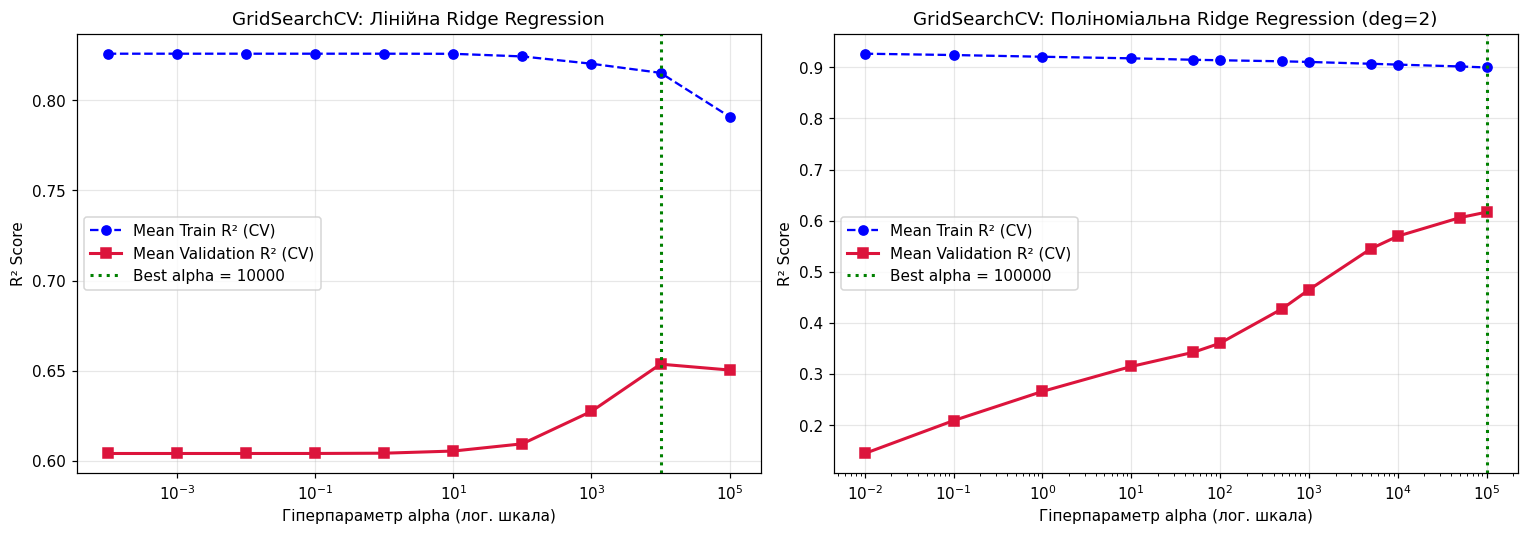

In [9]:
# Візуалізація залежності R^2 від гіперпараметра alpha у GridSearchCV
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

alphas1 = [p["alpha"] for p in Grid1.cv_results_["params"]]
axes[0].semilogx(alphas1, Grid1.cv_results_["mean_train_score"], "o--", color="blue", label="Mean Train R² (CV)")
axes[0].semilogx(alphas1, Grid1.cv_results_["mean_test_score"], "s-", color="crimson", linewidth=2, label="Mean Validation R² (CV)")
axes[0].axvline(Grid1.best_params_["alpha"], color="green", linestyle=":", linewidth=2, label=f"Best alpha = {Grid1.best_params_['alpha']}")
axes[0].set_xlabel("Гіперпараметр alpha (лог. шкала)")
axes[0].set_ylabel("R² Score")
axes[0].set_title("GridSearchCV: Лінійна Ridge Regression")
axes[0].legend()
axes[0].grid(alpha=0.3)

alphas2 = [p["alpha"] for p in Grid2.cv_results_["params"]]
axes[1].semilogx(alphas2, Grid2.cv_results_["mean_train_score"], "o--", color="blue", label="Mean Train R² (CV)")
axes[1].semilogx(alphas2, Grid2.cv_results_["mean_test_score"], "s-", color="crimson", linewidth=2, label="Mean Validation R² (CV)")
axes[1].axvline(Grid2.best_params_["alpha"], color="green", linestyle=":", linewidth=2, label=f"Best alpha = {Grid2.best_params_['alpha']}")
axes[1].set_xlabel("Гіперпараметр alpha (лог. шкала)")
axes[1].set_ylabel("R² Score")
axes[1].set_title("GridSearchCV: Поліноміальна Ridge Regression (deg=2)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

---

## 5. Контрольні запитання

### 1. Що таке Overfitting, Underfitting?
- **Overfitting (перенавчання)** — це явище, коли модель є занадто складною (має забагато вільних параметрів відносно кількості спостережень) і підлаштовується під випадковий шум та похибки тренувального набору даних замість того, щоб вивчати справжню базову закономірність. Ознака Overfitting: дуже висока точність (мала похибка, $R^2 \to 1$) на тренувальних даних і низька точність (велика похибка) на нових тестових даних.
- **Underfitting (недонавчання)** — це протилежне явище, коли модель є занадто простою (наприклад, лінійна модель для складної нелінійної залежності або модель з надмірною регуляризацією) і не здатна охопити основну структуру даних. Ознака Underfitting: низька точність (висока похибка, малий $R^2$) **як на тренувальних, так і на тестових даних**.

### 2. Що таке GridSearch?
**GridSearch (пошук по сітці, реалізований у `sklearn.model_selection.GridSearchCV`)** — це автоматизований метод підбору оптимальних **гіперпараметрів** моделі (параметрів, які не навчаються автоматично під час `.fit()`, наприклад коефіцієнта регуляризації $\alpha$ у `Ridge`). Користувач задає словник («сітку») можливих значень гіперпараметрів, після чого `GridSearchCV` перебирає всі можливі комбінації, оцінює кожну за допомогою крос-валідації (наприклад, за середнім $R^2$ або $\text{MSE}$) і автоматично обирає комбінацію з найкращим результатом (`best_params_`, `best_estimator_`).

### 3. Що таке Cross-Validation Score? Для чого він потрібен?
**Cross-Validation Score (оцінка перехресного затверджування / крос-валідації)** — це показник якості узагальнення моделі, отриманий шляхом розбиття вибірки даних на $k$ рівних взаємодоповнювальних частин (фолдів, наприклад $k=4$). Проводиться $k$ раундів: у кожному раунді $k-1$ частин використовують для тренування моделі, а $1$ частину, що залишилася — для тестування (валідації). Отримані $k$ оцінок усереднюють.
**Для чого він потрібен:**
1. Дає значно надійнішу та менш залежну від конкретного випадкового розбиття (`train_test_split`) оцінку того, як модель працюватиме на нових («небачених» позавибіркових) даних у реальному світі.
2. Дозволяє ефективно використовувати весь доступний обсяг даних і вчасно виявляти проблеми перенавчання (*overfitting*) та вибіркового упередження під час вибору моделі чи налаштування гіперпараметрів.